In [1]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from scipy.stats import shapiro, kstest, probplot
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.graphics.gofplots import qqplot


### Carga dos dados

In [2]:
# Abrindo o dataset
df_pontuacao = pd.read_csv('./datasets/pontuacao_teste.csv')

In [3]:
# Checar estrutura do dataset
df_pontuacao.info()

<class 'pandas.DataFrame'>
RangeIndex: 101 entries, 0 to 100
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   horas_estudo     101 non-null    float64
 1   pontuacao_teste  101 non-null    int64  
dtypes: float64(1), int64(1)
memory usage: 1.7 KB


In [4]:
# Vizualizar topo do dataframe
df_pontuacao.head()

,horas_estudo,pontuacao_teste
0,1.1,30
1,2.0,55
2,2.5,60
3,3.6,75
4,4.2,85


In [5]:
# Vizualizar fim do dataframe
df_pontuacao.tail()

,horas_estudo,pontuacao_teste
96,46.0,780
97,46.2,785
98,46.4,790
99,46.6,795
100,46.9,800


### EDA

In [6]:
# Medidas estatísticas das variáveis
df_pontuacao.describe()

,horas_estudo,pontuacao_teste
count,101.000000,101.000000
mean,28.604950,455.000000
std,14.116128,221.385411
min,1.100000,30.000000
25%,16.500000,270.000000
50%,30.900000,465.000000
75%,41.800000,655.000000
max,46.900000,800.000000


<Axes: xlabel='horas_estudo', ylabel='pontuacao_teste'>

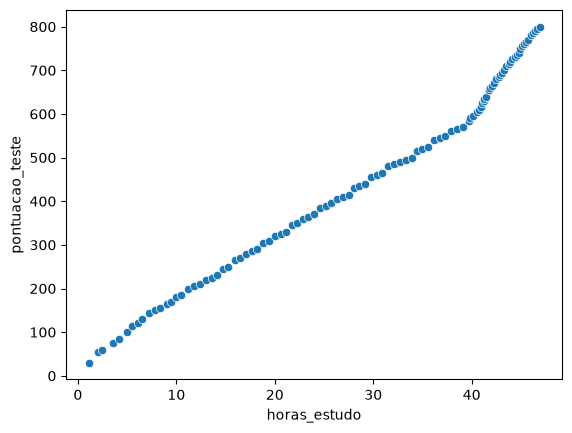

In [7]:
# Plot de Dispersão
# X = horas_estudo
# y = pontuacao_teste
sns.scatterplot(data=df_pontuacao, x='horas_estudo', y='pontuacao_teste')

<Axes: ylabel='horas_estudo'>

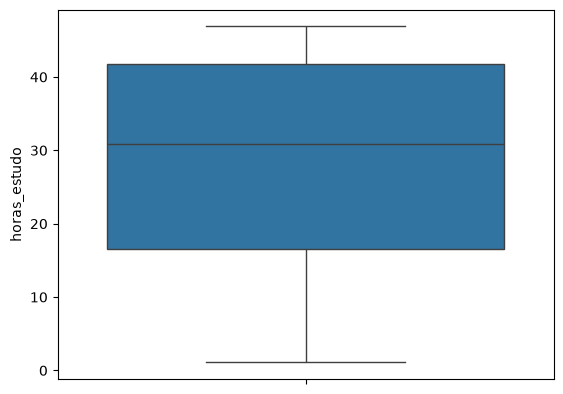

In [8]:
# Verificar se temos outliers
# Plot BoxPlot
sns.boxplot(df_pontuacao, y='horas_estudo')

<Axes: ylabel='pontuacao_teste'>

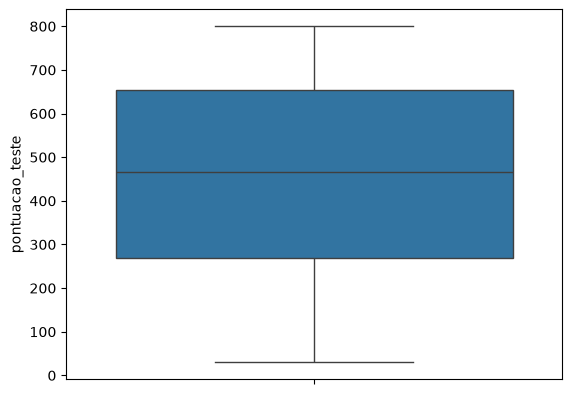

In [9]:
# Verificar se temos outliers
# Plot BoxPlot
sns.boxplot(df_pontuacao, y='pontuacao_teste')

<Axes: >

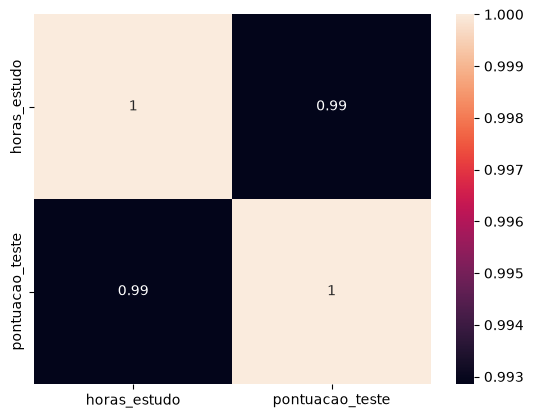

In [10]:
# Verificar Correlação - Pearson
sns.heatmap(df_pontuacao.corr('pearson'), annot = True)

<Axes: >

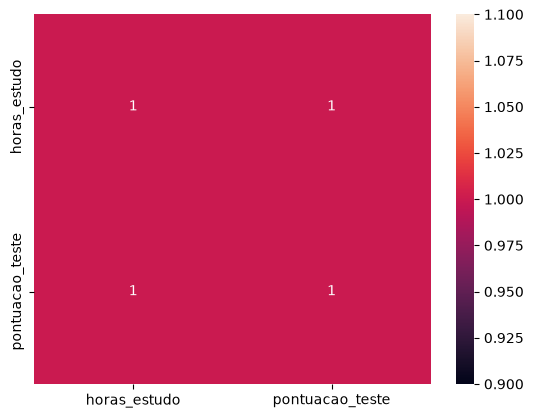

In [11]:
# Verificar Correlação - Pearson
sns.heatmap(df_pontuacao.corr('spearman'), annot = True)

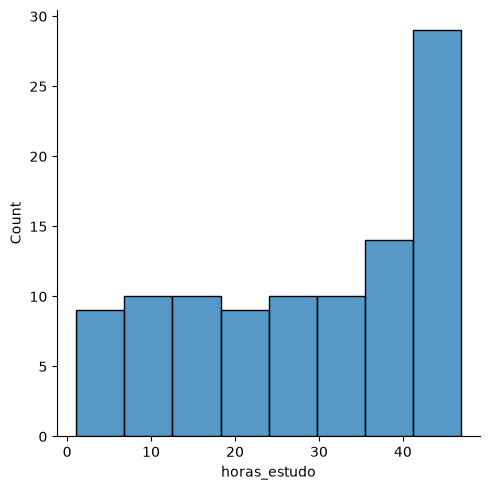

In [12]:
# Histograma das variáveis 
sns.displot(df_pontuacao, x='horas_estudo')

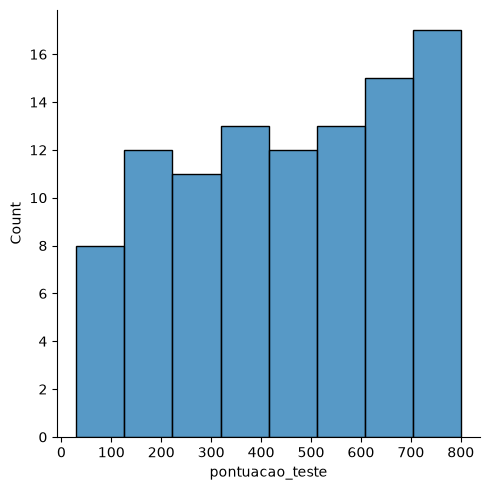

In [13]:
# Histograma das variáveis 
sns.displot(df_pontuacao, x='pontuacao_teste')

### Treinar modelo

In [14]:
# Dividir dataset entre treino e teste
# Quando temos apenas uma feature, precisamos ajustar o shape
X = df_pontuacao['horas_estudo'].values.reshape(-1,1)
y = df_pontuacao['pontuacao_teste'].values.reshape(-1,1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=50)

In [15]:
# Instanciar o modelo a ser treinado 
reg_model = LinearRegression()

In [16]:
# Treinar o modelo
reg_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[15.64]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[8.48]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[118.92]


In [17]:
# Imprimir a equação da reta
# y = aX + b
print("A equação da reta é y = {:4f}x + {:4f}".format(reg_model.coef_[0][0], reg_model.intercept_[0]))

A equação da reta é y = 15.642619x + 8.476601


### Validar Modelo - Métricas

In [18]:
# Predição dos valores com base no conjunto de testes 
y_pred = reg_model.predict(X_test)

In [26]:
# Calcular métrica R-squared ou Coeficiente de Determinação 
# R2 representa a proporção na variação na variável dependente que é explicada pela variável independente
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, root_mean_squared_error
r2_score(y_test, y_pred)

0.9828400452912442

In [22]:
# Calcular métrica MAE (Mean Absolute Error)
# MAE = Media (y_test - y_pred)
# É uma métrica fácil de interpretar 
# MAE é menos sensível a outliers 
mean_absolute_error(y_test, y_pred)

22.957470277134615

In [23]:
# Calcular métrica MSE (Mean Squared Error)
# MSE = Média (y_test - y_pred)^2
# Não é uma métrica fácil de interpretar 
# MSE é mais sensível a outliers e penaliza grandes erros 
mean_squared_error(y_test, y_pred)

766.9972992416427

In [27]:
# Calcular métrica RMSE (Square Root Squared Error)
# MSE = Raiz (Média (y_test - y_pred)^2)
#  é uma métrica fácil de interpretar 
# MSE é mais sensível a outliers e penaliza grandes erros 
root_mean_squared_error(y_test,y_pred)

27.69471608884342

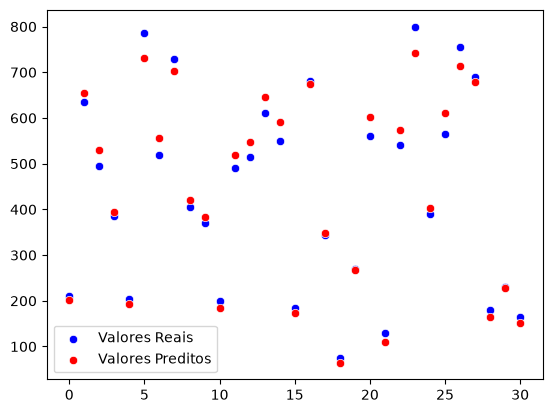

In [28]:
# Analise Gráfica 
x_axis = range(len(y_test))
plt.Figure(figsize=(10,6))
sns.scatterplot(x=x_axis, y=y_test.reshape(-1), color='blue', label='Valores Reais')
sns.scatterplot(x=x_axis, y=y_pred.reshape(-1), color='red', label='Valores Preditos')
plt.legend()
plt.show()

### Análise de Resíduos

In [29]:
# Calcular residuos
residuos = y_test - y_pred

In [30]:
# Calcular os resíduos padronizados (standardization)
# Para cada elemento de um conjunto (X - media) / desvio padrão
from scipy.stats import zscore
residuos_std = zscore(residuos)

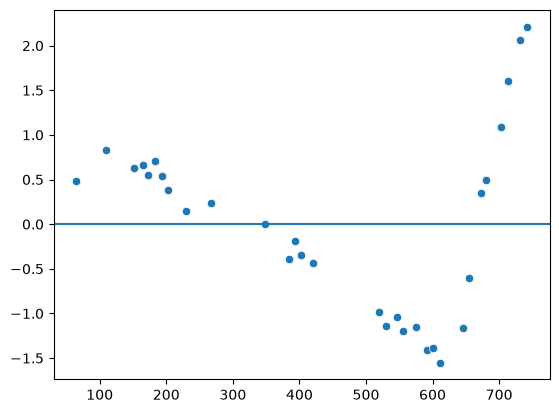

In [32]:
# Verificar linearidade do modelo: 
# Se os resíduos estiverem entre - 2 e +2 (na escala padrão) - indica linearidade
# Verificar homogeneidade das variãncias (Homocedasticidade)
# Valores estiverem em torno da reta, temos homocedasticidade, caso contrario
# Se tivemos alguma tendência ou padrão forma um cone, funil, há heterocedasticidade

sns.scatterplot(x=y_pred.reshape(-1), y=residuos_std.reshape(-1))
plt.axhline(y=0)

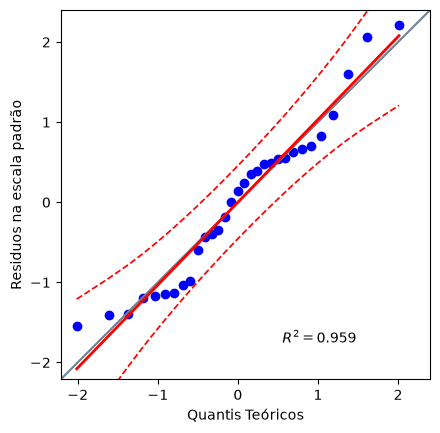

In [33]:
# Checar se residuos seguem uma distribuição normal
# QQ (quantile-quantile) Plot, que avalia se uma amostra segue uma distribuição normal 
import pingouin as pg
pg.qqplot(residuos_std, dist='norm', confidence=0.95)
plt.xlabel('Quantis Teóricos')
plt.ylabel('Residuos na escala padrão')
plt.show()

In [34]:
# Teste de normalidade - Shapiro Wilk 
# H0 - Segue distribuição normal
# H1 - Não segue distribuição normal
# Se o p-valor > 0.05 não rejeita, caso contrario rejeitamos
stat_shapiro, p_valor_shapiro = shapiro(residuos.reshape(-1))
print("Estatística do teste: {} e P-valor: {}".format(stat_shapiro, p_valor_shapiro))

Estatística do teste: 0.9500532224627557 e P-valor: 0.15663817697933435


In [35]:
# Teste de normalidade - Kolmogorov-Smirnov
# H0 - Segue distribuição normal
# H1 - Não segue distribuição normal
# Se o p-valor > 0.05 não rejeita, caso contrario rejeitamos
stat_ks, p_valor_ks = kstest(residuos.reshape(-1), 'norm')
print("Estatística do teste: {} e P-valor: {}".format(stat_ks, p_valor_ks))

Estatística do teste: 0.48355808450512827 e P-valor: 3.395368995814077e-07


### Fazer predições com o modelo 

In [38]:
# Se eu estudar 30.4 horas, qual a pontuação prevista pelo modelo?
reg_model.predict([[30.4]])

array([[484.01220436]])

In [40]:
# Quantas horas estudar para obter 600 pontos (pelo modelo) ?
# y = aX + b 
# y - b = aX -> (y - b) / a = X -> X = (y - b) / a
(600 - reg_model.intercept_[0]) / reg_model.coef_[0][0]


np.float64(37.81485802710669)

### Salvar modelo para usar depois

In [41]:
import joblib
joblib.dump(reg_model, './modelo_regressao_linear.pkl')

['./modelo_regressao_linear.pkl']